# Stan 1D Gaussian Random Restarts (100 observations)

Same as `rr_stan.ipynb`, but with the 100-observation 1d Gaussian (`gaussian_1d(100, 3, 1.0, seed=0)`) that the bias heatmaps used before they switched to no observations. Results and figures are written to `*_100obs` paths so they don't overwrite the no-observation ones. The later cells of `rr_stan.ipynb` that reload separate no-observation runs are left out.

Runs Stan ADVI random restarts using prefix-length reruns so final variational draws provide trajectory checkpoints.

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd

REL_DIR = Path("single_MC/1dgaussian_knownvar/random_restarts")
STAN_FILE_NAME = "stan_1dgaussian_knownvar.stan"


def find_notebook_dir():
    cwd = Path.cwd().resolve()
    candidates = [cwd, cwd / REL_DIR]
    candidates.extend(parent for parent in cwd.parents)
    candidates.extend(parent / REL_DIR for parent in cwd.parents)
    for candidate in candidates:
        if (candidate / STAN_FILE_NAME).exists():
            return candidate.resolve()
    raise FileNotFoundError(f"Could not find {STAN_FILE_NAME} from {cwd}")


NOTEBOOK_DIR = find_notebook_dir()
os.chdir(NOTEBOOK_DIR)

REPO_ROOT = NOTEBOOK_DIR
while not (REPO_ROOT / "modulars").exists():
    if REPO_ROOT.parent == REPO_ROOT:
        raise FileNotFoundError("Could not locate repo root containing modulars/")
    REPO_ROOT = REPO_ROOT.parent

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

STAN_FILE = NOTEBOOK_DIR / STAN_FILE_NAME
print(f"Notebook dir: {NOTEBOOK_DIR}")
print(f"Stan model: {STAN_FILE}")

if Path(sys.prefix).name != "stan3":
    raise RuntimeError(
        f"This notebook must run in the miniconda environment named stan3; "
        f"current sys.prefix is {sys.prefix!r}."
    )

STAN3_PREFIX = Path(sys.prefix).resolve()
STAN3_CMDSTAN = STAN3_PREFIX / "bin" / "cmdstan"
if not STAN3_CMDSTAN.exists():
    raise FileNotFoundError(f"Expected CmdStan at {STAN3_CMDSTAN}")

os.environ["CMDSTAN"] = str(STAN3_CMDSTAN)
from cmdstanpy import cmdstan_path, set_cmdstan_path
set_cmdstan_path(str(STAN3_CMDSTAN))

print(f"Python executable: {sys.executable}")
print(f"CmdStan path: {cmdstan_path()}")


Notebook dir: <repo>/single_MC/1dgaussian_knownvar/random_restarts
Stan model: <repo>/single_MC/1dgaussian_knownvar/random_restarts/stan_1dgaussian_knownvar.stan
Python executable: <conda>/envs/stan3/bin/python
CmdStan path: <conda>/envs/stan3/bin/cmdstan


<conda>/envs/stan3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from modulars import gaussian_1d, gaussian_1d_posterior

mu_prior, sigma_prior = 0.0, 10.0
sigma_like = 1.0
n_samples = 100  # the 100-observation setup the bias heatmaps used before switching to
                 # no observations; rr_stan.ipynb uses n_samples=0 to avoid an eta-search instability
mu_like = 3.0

data = gaussian_1d(n_samples, mu_like, sigma_like, seed=0).astype(np.float32)
true_mu_post, true_sigma_post = gaussian_1d_posterior(
    data,
    n_samples=n_samples,
    mu_prior=mu_prior,
    sigma_prior=sigma_prior,
    sigma_like=sigma_like,
)

stan_data = {
    "N": len(data),
    "y": data,
    "sigma_like": sigma_like,
    "mu_prior": mu_prior,
    "sigma_prior": sigma_prior,
}
PARAM_COLUMNS = ["mu"]
LOG_COLUMNS = []
true_mu_post, true_sigma_post


(np.float32(3.059502), np.float64(0.09999500037496875))

In [3]:
from pathlib import Path

RUN_MODE = os.environ.get("SIMPLEVI_STAN_RUN_MODE", "full")  # "quick" or "full"
RUN_CONFIGS = {
    "quick": {"max_iters": 20, "n_restarts": 1, "track_every": 10, "parallel": False, "max_workers": None, "keep_outputs": True},
    "full": {"max_iters": 50_000, "n_restarts": 20, "track_every": 10, "parallel": True, "max_workers": 4, "keep_outputs": False},
}

run_config = RUN_CONFIGS[RUN_MODE]
max_iters = int(os.environ.get("SIMPLEVI_STAN_MAX_ITERS", run_config["max_iters"]))
n_restarts = int(os.environ.get("SIMPLEVI_STAN_N_RESTARTS", run_config["n_restarts"]))
track_every = int(os.environ.get("SIMPLEVI_STAN_TRACK_EVERY", run_config["track_every"]))
parallel = bool(int(os.environ.get("SIMPLEVI_STAN_PARALLEL", int(run_config["parallel"]))))
max_workers_env = os.environ.get("SIMPLEVI_STAN_MAX_WORKERS")
max_workers = int(max_workers_env) if max_workers_env else run_config["max_workers"]
keep_outputs = bool(int(os.environ.get("SIMPLEVI_STAN_KEEP_OUTPUTS", int(run_config["keep_outputs"]))))

results_dir = Path(os.environ.get("SIMPLEVI_STAN_RESULTS_DIR", "stan_cmdstan_output_100obs"))
results_dir.mkdir(exist_ok=True, parents=True)

# Skip rerunning Stan entirely and just reload the last saved by-scenario
# result (see BY_SCENARIO_PATH / save_stan_by_scenario below) for plotting.
LOAD_SAVED = bool(int(os.environ.get("SIMPLEVI_STAN_LOAD_SAVED", "0")))

run_config | {"parallel": parallel, "max_workers": max_workers, "results_dir": str(results_dir), "load_saved": LOAD_SAVED}


{'max_iters': 50000,
 'n_restarts': 20,
 'track_every': 10,
 'parallel': True,
 'max_workers': 4,
 'keep_outputs': False,
 'results_dir': 'stan_cmdstan_output_100obs',
 'load_saved': True}

In [4]:
from modulars.stan_rr_test import (
    run_stan_random_restarts, stan_result_tuple, FIVE_WAY_STAN_SCENARIOS,
    stan_result_by_scenario, save_stan_by_scenario, load_stan_by_scenario,
)

SCENARIO_MC_LABELS = {s["name"]: str(s.get("mc_label", s["name"])) for s in FIVE_WAY_STAN_SCENARIOS}
BY_SCENARIO_PATH = Path(os.environ.get("SIMPLEVI_STAN_TRACKING_DIR", "processed_tracking")) / "rr_stan_by_scenario_100obs.npz"

# default and grad100_default_rest run for 20k iterations here; the other
# three scenarios keep FIVE_WAY_STAN_SCENARIOS' max_iters_scale.
RERUN_20K_SCENARIOS = {"default", "grad100_default_rest"}
scenarios = tuple(
    {**s, "max_iters_scale": 20_000 / max_iters} if s["name"] in RERUN_20K_SCENARIOS else s
    for s in FIVE_WAY_STAN_SCENARIOS
)

# Comma-separated scenario names to (re)run this pass; unset runs all five.
# Scenarios left out are reused from the cached by-scenario result on disk
# instead of being rerun -- e.g. SIMPLEVI_STAN_RERUN_SCENARIOS=default,grad100_default_rest
# reruns just those two (at the 20k above) and merges them into the other
# three scenarios' cached results.
rerun_only_env = os.environ.get("SIMPLEVI_STAN_RERUN_SCENARIOS")
rerun_only = {name.strip() for name in rerun_only_env.split(",")} if rerun_only_env else None

scenarios = scenarios + ({
    "name": "tol_1e-6_default_rest",
    "mc_label": "tol_1e-6_default_rest",
    "cmd_args": (),
    "tol_rel_obj": 1e-6,
    "max_iters_scale": 75_000 / max_iters,
    "track_every_scale": 150 / track_every,
},)

if LOAD_SAVED:
    stan_result = None
    by_scenario = load_stan_by_scenario(BY_SCENARIO_PATH)
    print(f"Loaded cached by-scenario result from {BY_SCENARIO_PATH}; Stan was not rerun.")
else:
    scenarios_to_run = tuple(s for s in scenarios if rerun_only is None or s["name"] in rerun_only)
    stan_result = run_stan_random_restarts(
        stan_file=STAN_FILE,
        data=stan_data,
        param_columns=PARAM_COLUMNS,
        log_columns=LOG_COLUMNS,
        output_dir=results_dir / "cmdstan_runs",
        max_iters=max_iters,
        n_restarts=n_restarts,
        track_every=track_every,
        seed_offset=100,
        parallel=parallel,
        max_workers=max_workers,
        keep_outputs=keep_outputs,
        refresh=0,
        dtype=np.float64,
        scenarios=scenarios_to_run,
    )
    by_scenario = stan_result_by_scenario(stan_result)
    if rerun_only is not None:
        cached = load_stan_by_scenario(BY_SCENARIO_PATH)
        cached.update(by_scenario)
        by_scenario = cached
    save_stan_by_scenario(BY_SCENARIO_PATH, by_scenario)
    print(f"Saved by-scenario result to {BY_SCENARIO_PATH}; "
          f"set SIMPLEVI_STAN_LOAD_SAVED=1 to reload it without rerunning Stan.")


Loaded cached by-scenario result from processed_tracking/rr_stan_by_scenario_100obs.npz; Stan was not rerun.


In [5]:
default_means, default_stds, default_iterations = by_scenario["default"]
grad100_means, grad100_stds, grad100_iterations = by_scenario["grad100_default_rest"]
adapt_off_means, adapt_off_stds, adapt_off_iterations = by_scenario["grad100_adapt_off"]
tol_means, tol_stds, tol_iterations = by_scenario["grad100_tol_rel_obj1e-6"]
eta_tol_means, eta_tol_stds, eta_tol_iterations = by_scenario["grad100_tol_rel_obj1e-6_eta0.01"]
tol_default_means, tol_default_stds, tol_default_iterations = by_scenario["tol_1e-6_default_rest"]


from modulars.plot_rr import plot_a_few_trajectories_1d, plot_mean_band_rrs_1d

# "matplotlib" (default, static, savable via plt.savefig) or "plotly"
# (interactive: zoom/pan/hover, shown inline). Flip this and rerun the
# plotting cells below to switch how every plot in this notebook renders.
PLOT_BACKEND = "plotly"

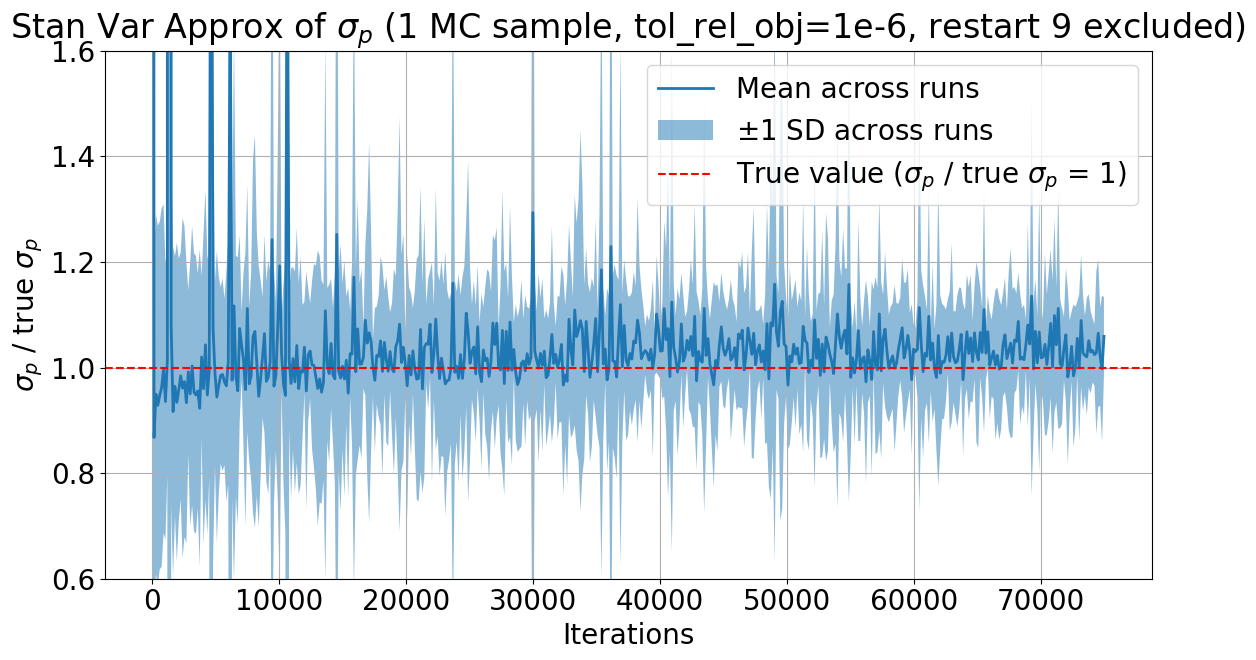

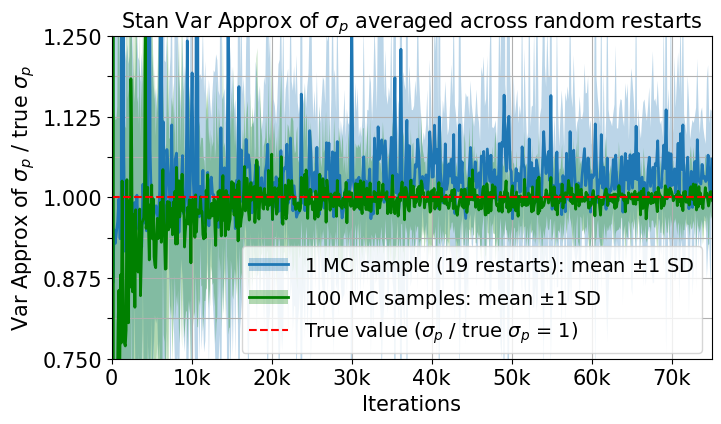

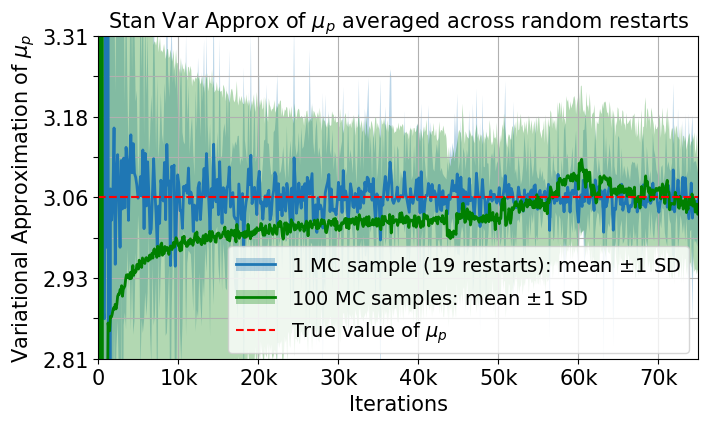

In [6]:
import matplotlib.pyplot as plt
from modulars.plot_rr import plot_mean_band

# mean +-1 SD (across restarts) of the posterior sd for tol_1e-6_default_rest
# (1 MC sample, tol_rel_obj=1e-6, 75k iterations tracked every 150)
# restart 9 (index 8) blew up in eta adaptation (sd ~6e-14, mu ~322; see the
# per-restart grid below), so it is left out of the tol_1e-6_default_rest means
tol_default_stds_kept = np.delete(tol_default_stds, 8, axis=0)
tol_default_means_kept = np.delete(tol_default_means, 8, axis=0)
# the sigma_p figures plot the variational sd divided by the true sigma_p, so
# the true value is at 1

plt.rcParams.update({"font.size": 20})
fig, ax = plt.subplots(figsize=(12, 7))
plot_mean_band(
    ax, tol_default_iterations, tol_default_stds_kept / true_sigma_post, 1.0,
    r"Stan Var Approx of $\sigma_p$ (1 MC sample, tol_rel_obj=1e-6, restart 9 excluded)",
    r"$\sigma_p$ / true $\sigma_p$",
)
# plot_mean_band labels the reference line "Best value" and the x axis
# "Iteration"; relabel them here
ax.lines[-1].set_label(r"True value ($\sigma_p$ / true $\sigma_p$ = 1)")
ax.set_xlabel("Iterations")
ax.legend()
ax.set_ylim(0.6, 1.6)
plt.tight_layout()
plt.show()


# mean (across restarts) trajectory, with a lighter +-1 SD (across restarts)
# band, for a 1 MC sample and a 100 MC sample scenario on one plot. Font
# sizes, y axis and axes box match the PyMC 3_1 figures.
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import ScaledTranslation

FONT_SIZE = 15
n_shared = min(len(default_iterations), len(grad100_iterations))
x_shared = default_iterations[:n_shared]


def plot_default_vs_grad100(default_trajs, grad100_trajs, true_value, symbol, out_name,
                            half_width=1.0, label_fmt=".1f", default_x=None, grad100_x=None,
                            x_max=20_000, default_label="Default (1 MC sample)",
                            grad100_label="Adjusted (100 MC samples)", ylabel=None, true_label=None):
    # without explicit iteration grids, both scenarios are truncated to the shared grid
    if default_x is None:
        default_trajs, default_x = default_trajs[:, :n_shared], x_shared
    if grad100_x is None:
        grad100_trajs, grad100_x = grad100_trajs[:, :n_shared], x_shared
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    legend_handles, legend_labels = [], []
    for trajs, x, color, section in (
        (default_trajs, default_x, "tab:blue", default_label),
        (grad100_trajs, grad100_x, "green", grad100_label),
    ):
        m = np.nanmean(trajs, axis=0)
        s = np.nanstd(trajs, axis=0)
        ax.plot(x, m, color=color, linewidth=2)
        ax.fill_between(x, m - s, m + s, color=color, alpha=0.3, linewidth=0)
        # one entry drawing the mean line over the +-1 SD shade
        legend_handles.append((Patch(color=color, alpha=0.3, linewidth=0), Line2D([], [], color=color, linewidth=2)))
        legend_labels.append(section + r": mean $\pm$1 SD")
    ax.axhline(true_value, color="red", linestyle="--")
    legend_handles.append(Line2D([], [], color="red", linestyle="--"))
    legend_labels.append(true_label or rf"True value of ${symbol}$")
    # true value +-half_width, 9 ticks, every other one labelled
    offsets = np.linspace(-half_width, half_width, 9)
    ax.set_yticks(true_value + offsets,
                  [f"{true_value + o:{label_fmt}}" if i % 2 == 0 else None for i, o in enumerate(offsets)])
    ax.set_ylim(true_value - half_width, true_value + half_width)
    ax.tick_params(labelsize=FONT_SIZE)
    ax.set_xlim(0, x_max)
    ax.xaxis.set_major_formatter(lambda x, pos: "0" if x == 0 else f"{x / 1000:g}k")
    ax.set_title(rf"Stan Var Approx of ${symbol}$ averaged across random restarts", fontsize=FONT_SIZE)
    ax.set_xlabel("Iterations", fontsize=FONT_SIZE)
    ax.set_ylabel(ylabel or rf"Variational Approximation of ${symbol}$", fontsize=FONT_SIZE)
    ax.grid()
    # lower right, nudged 0.1 cm down from matplotlib's default placement there
    ax.legend(
        legend_handles, legend_labels, fontsize=FONT_SIZE - 1, loc="lower right", bbox_to_anchor=(1, 0),
        bbox_transform=ax.transAxes + ScaledTranslation(0, -0.1 / 2.54, fig.dpi_scale_trans),
    )
    # fixed axes box taken from the PyMC 3_1 sigma_p figure's tight_layout, so the
    # saved PNGs have identically sized and placed plot areas
    fig.subplots_adjust(left=0.1479, right=0.9479, bottom=0.1728, top=0.8904)
    plt.savefig(NOTEBOOK_DIR / out_name, dpi=300)
    plt.show()


# both figures compare the two tol_rel_obj=1e-6 scenarios, each on its own
# iteration grid (75k every 150 and 200k every 100), shown out to the shorter
# 75k; sigma_p is divided by the true sigma_p, mu_p is left unscaled
TOL_LABELS = dict(default_x=tol_default_iterations, grad100_x=tol_iterations, x_max=75_000,
                  default_label="1 MC sample (19 restarts)", grad100_label="100 MC samples")
plot_default_vs_grad100(tol_default_stds_kept / true_sigma_post, tol_stds / true_sigma_post, 1.0, r"\sigma_p",
                        "stan_facct_2_100obs.png", half_width=0.25, label_fmt=".3f",
                        ylabel=r"Var Approx of $\sigma_p$ / true $\sigma_p$",
                        true_label=r"True value ($\sigma_p$ / true $\sigma_p$ = 1)", **TOL_LABELS)
plot_default_vs_grad100(tol_default_means_kept, tol_means, true_mu_post, r"\mu_p", "stan_facct_mu_100obs.png",
                        half_width=0.25, label_fmt=".2f", **TOL_LABELS)

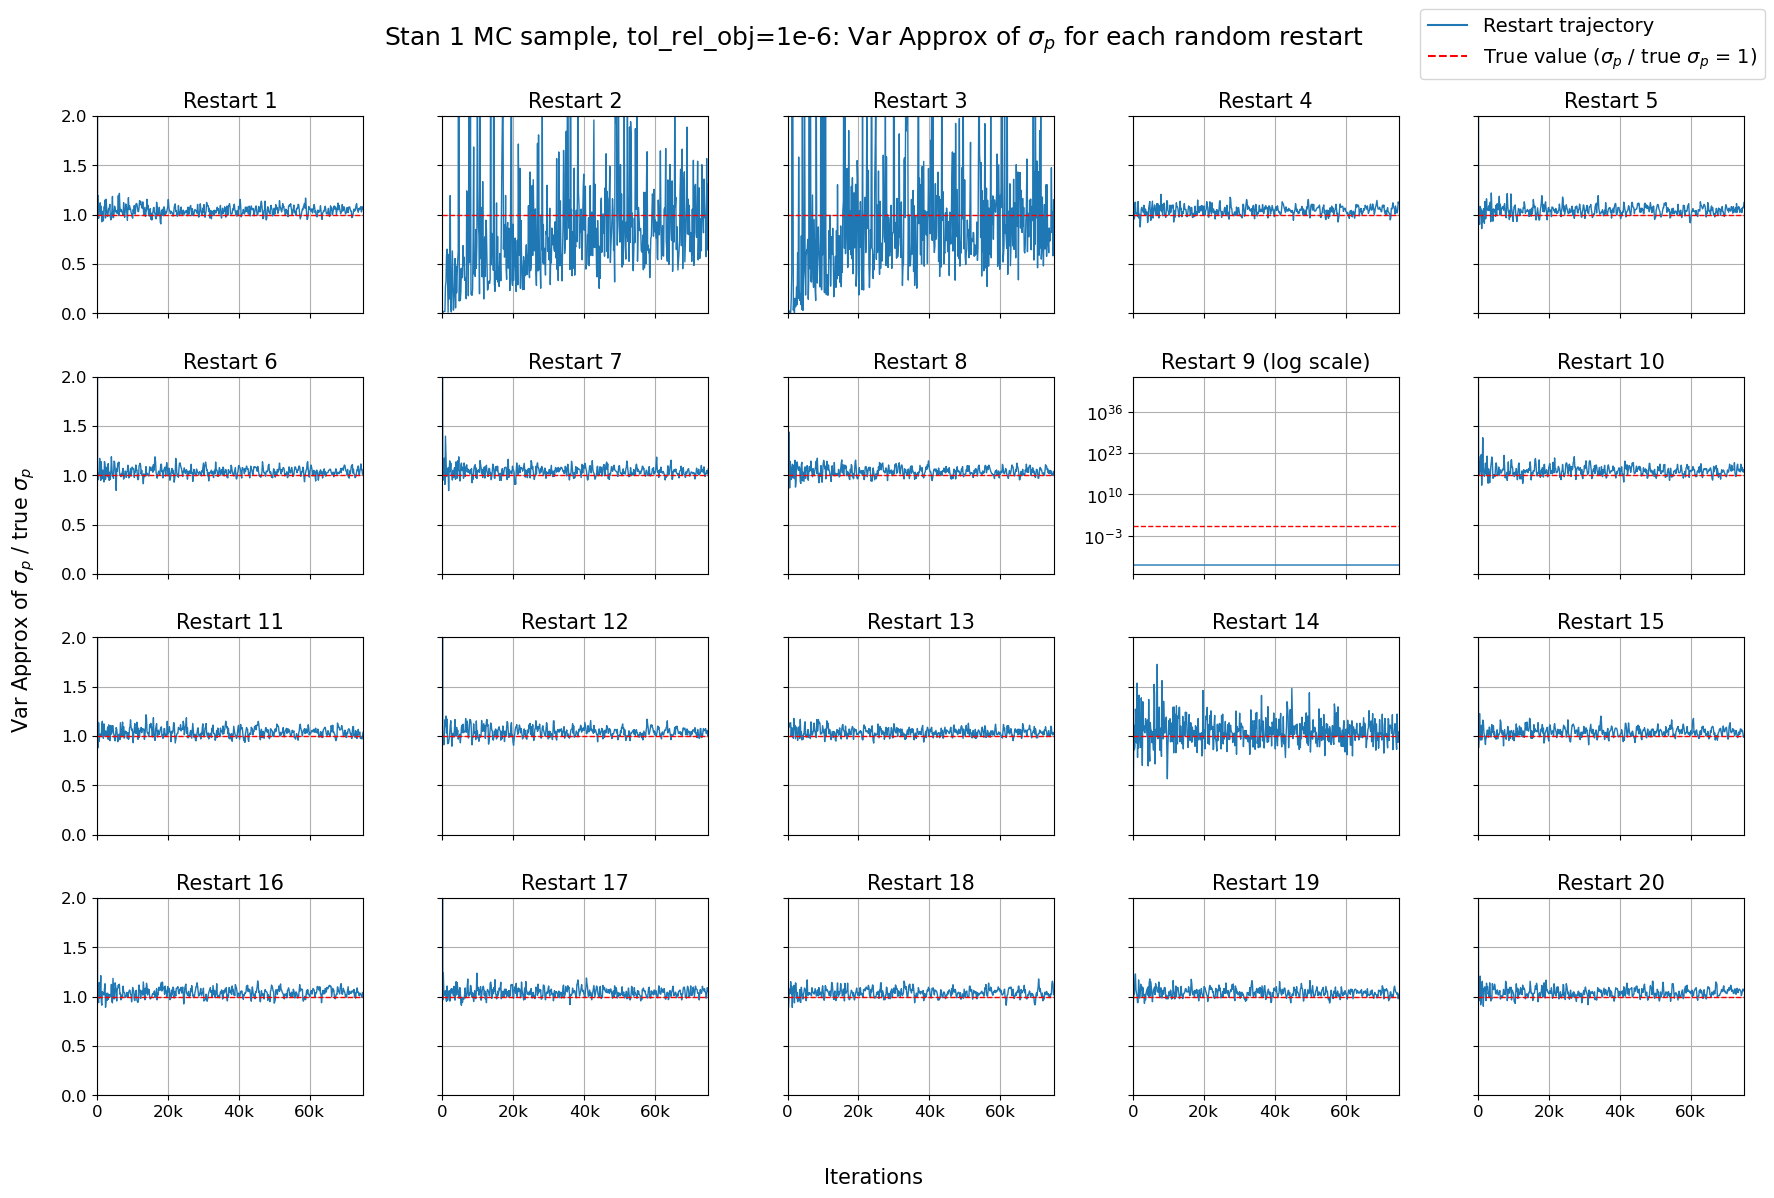

In [7]:
# each tol_1e-6_default_rest (1 MC sample, tol_rel_obj=1e-6) restart's
# posterior-sd trajectory on its own panel: the 20 restarts averaged into
# the first mean +-1 SD figure above
n_restarts_grid = tol_default_stds.shape[0]
# restart 9 (index 8) blew up in eta adaptation: its sd is ~1e43 at iteration 1
# and ~6e-14 afterwards, so it gets its own log-scale y axis; the rest share
# the zoomed linear range below. Sds are divided by the true sigma_p, so the
# true value is at 1
BLOWUP_RESTART = 8
fig, axs = plt.subplots(4, 5, figsize=(18, 12), sharex=True)
for i, ax in enumerate(axs.flat):
    if i >= n_restarts_grid:
        ax.set_visible(False)
        continue
    ax.plot(tol_default_iterations, np.ravel(tol_default_stds[i]) / true_sigma_post, color="tab:blue", linewidth=1)
    ax.axhline(1.0, color="red", linestyle="--", linewidth=1)
    ax.set_title(f"Restart {i + 1}", fontsize=FONT_SIZE)
    ax.grid()
    ax.tick_params(labelsize=FONT_SIZE - 3)
    if i == BLOWUP_RESTART:
        ax.set_yscale("log")
        ax.set_title(f"Restart {i + 1} (log scale)", fontsize=FONT_SIZE)
        continue
    # zoomed to the 100-observation posterior sd; early spikes that leave
    # this range are clipped
    ax.set_ylim(0, 2)
    if i % axs.shape[1] != 0:
        ax.tick_params(labelleft=False)
axs[0, 0].set_xlim(0, tol_default_iterations[-1])
axs[0, 0].xaxis.set_major_formatter(lambda x, pos: "0" if x == 0 else f"{x / 1000:g}k")
fig.suptitle(r"Stan 1 MC sample, tol_rel_obj=1e-6: Var Approx of $\sigma_p$ for each random restart", fontsize=FONT_SIZE + 3)
fig.supxlabel("Iterations", fontsize=FONT_SIZE)
fig.supylabel(r"Var Approx of $\sigma_p$ / true $\sigma_p$", fontsize=FONT_SIZE)
fig.legend([Line2D([], [], color="tab:blue"), Line2D([], [], color="red", linestyle="--")],
           ["Restart trajectory", r"True value ($\sigma_p$ / true $\sigma_p$ = 1)"],
           loc="upper right", fontsize=FONT_SIZE - 1)
plt.tight_layout()
plt.show()

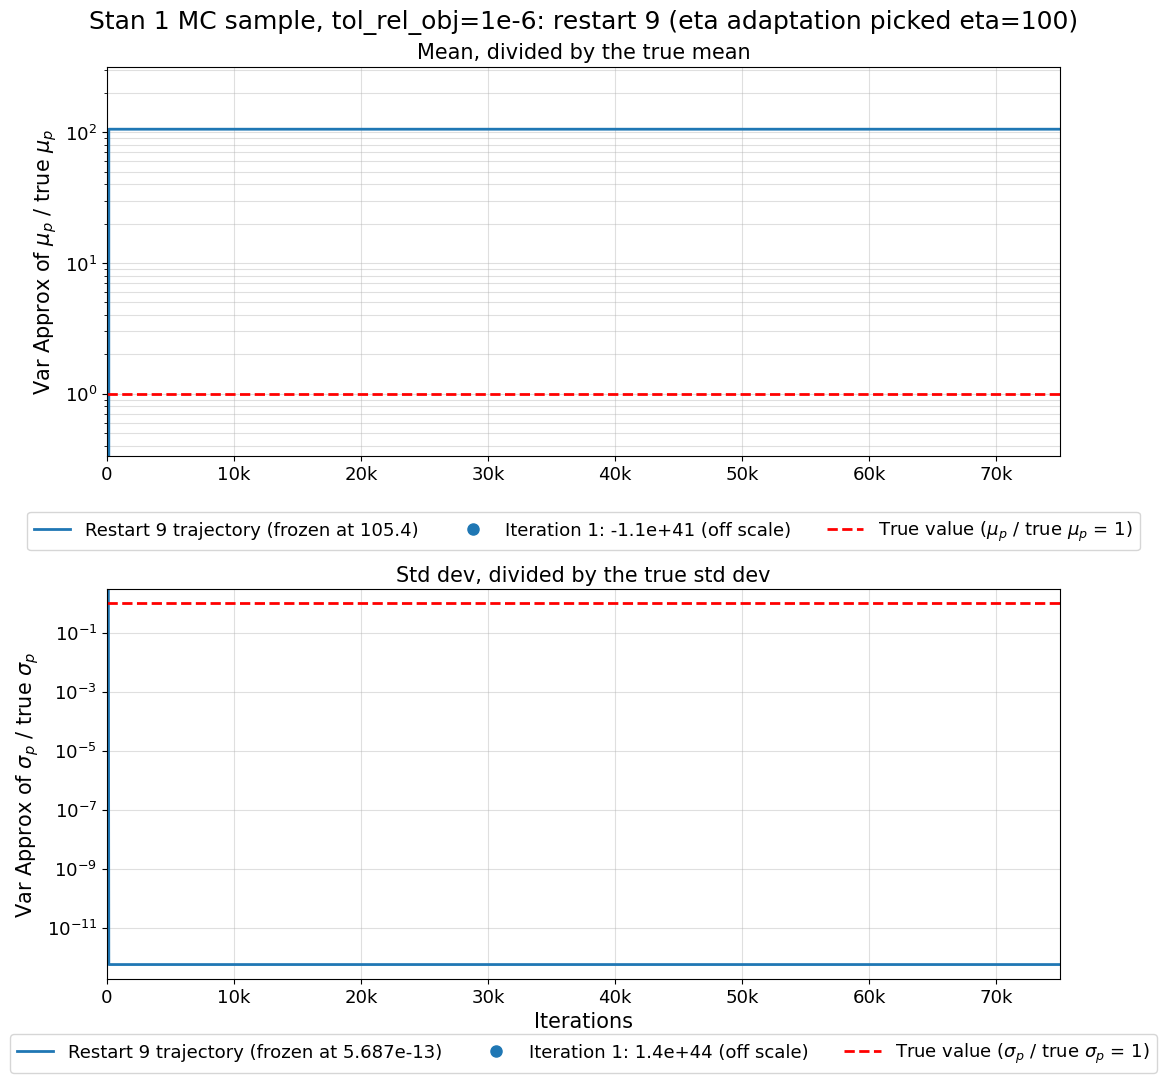

In [8]:
# restart 9 (index 8) of tol_1e-6_default_rest on its own: eta adaptation
# picked eta=100, so iteration 1 overshoots and every later prefix rerun
# freezes. Both are divided by their true values (mu_p, sigma_p), so the true
# values are at 1. Log y axes zoomed to the true value and the frozen value, so
# the iteration-1 point is off scale and cut off (its value is in the legend;
# the mean's is negative, so the log axis can't draw it at all)
r9_means = np.ravel(tol_default_means[8]) / true_mu_post
r9_stds = np.ravel(tol_default_stds[8]) / true_sigma_post
fig, (ax_mu, ax_sd) = plt.subplots(2, 1, figsize=(12, 11), sharex=True)
for ax, traj, ylabel, true_label in (
    (ax_mu, r9_means, r"Var Approx of $\mu_p$ / true $\mu_p$", r"True value ($\mu_p$ / true $\mu_p$ = 1)"),
    (ax_sd, r9_stds, r"Var Approx of $\sigma_p$ / true $\sigma_p$", r"True value ($\sigma_p$ / true $\sigma_p$ = 1)"),
):
    ax.set_yscale("log")
    lo, hi = min(traj[-1], 1.0) / 3, max(traj[-1], 1.0) * 3
    ax.set_ylim(lo, hi)
    ax.plot(tol_default_iterations, traj, color="tab:blue", linewidth=2,
            label=f"Restart 9 trajectory (frozen at {traj[-1]:.4g})")
    ax.plot(tol_default_iterations[0], traj[0], "o", color="tab:blue", markersize=8,
            label=f"Iteration 1: {traj[0]:.2g} (off scale)")
    ax.axhline(1.0, color="red", linestyle="--", linewidth=2, label=true_label)
    ax.set_ylabel(ylabel, fontsize=FONT_SIZE)
    ax.tick_params(labelsize=FONT_SIZE - 2)
    ax.grid(which="both", alpha=0.4)
    # below the axes, so it doesn't cover the trajectories
    ax.legend(fontsize=FONT_SIZE - 2, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
ax_mu.set_title("Mean, divided by the true mean", fontsize=FONT_SIZE)
ax_sd.set_title("Std dev, divided by the true std dev", fontsize=FONT_SIZE)
ax_mu.tick_params(labelbottom=True)
ax_sd.set_xlim(0, tol_default_iterations[-1])
ax_sd.xaxis.set_major_formatter(lambda x, pos: "0" if x == 0 else f"{x / 1000:g}k")
ax_sd.set_xlabel("Iterations", fontsize=FONT_SIZE)
fig.suptitle("Stan 1 MC sample, tol_rel_obj=1e-6: restart 9 (eta adaptation picked eta=100)", fontsize=FONT_SIZE + 3)
plt.tight_layout()
plt.show()
